In [1]:
import torch
import numpy as np
import torch.nn as nn

In [9]:
a = torch.tensor([1.0,2.0,3.0])
b = torch.zeros(2,3)  #2行3列 全零数组
c = torch.randn(2,3)  #2行3列 标准正态分布随机数组
d = torch.from_numpy(np.array([1,2,3])) #从numpy转换
print("a =", a, "| shape =", a.shape, "| dtype =", a.dtype)
print("b =\\n", b)
print("c =\\n", c)
print("d =\\n", d)
print(b.shape)

a = tensor([1., 2., 3.]) | shape = torch.Size([3]) | dtype = torch.float32
b =\n tensor([[0., 0., 0.],
        [0., 0., 0.]])
c =\n tensor([[ 0.4941, -0.8848, -1.8822],
        [-0.4396,  0.2542, -1.2721]])
d =\n tensor([1, 2, 3])
torch.Size([2, 3])


In [4]:
x = torch.arange(12) # [0..11]
x_reshape = x.view(3,4) # 3行4列
x_unsqueezed = x.unsqueeze(0) 
x_unsqueezed2 = x.unsqueeze(1)
print(x.shape)
print('\n')
print(x_unsqueezed.shape)
print('\n')
print(x_unsqueezed2.shape)

'''

二维张量增加维度
x = torch.randn(3, 4)  # 张量形状 (3, 4)
y = x.unsqueeze(0)     # 在第0维增加维度
print(y.shape)         # 输出 (1, 3, 4)
z = x.unsqueeze(1)     # 在第1维增加维度
print(z.shape)         # 输出 (3, 1, 4)

一维张量增加维度
input = torch.arange(0, 6)  # 形状 (6,)
output = input.unsqueeze(0) # 在最外层增加维度
print(output.shape)          # 输出 (1, 6)
output2 = input.unsqueeze(1) # 在第1维增加维度
print(output2.shape)         # 输出 (6, 1)

'''

torch.Size([12])


torch.Size([1, 12])


torch.Size([12, 1])


'\n\n二维张量增加维度\nx = torch.randn(3, 4)  # 张量形状 (3, 4)\ny = x.unsqueeze(0)     # 在第0维增加维度\nprint(y.shape)         # 输出 (1, 3, 4)\nz = x.unsqueeze(1)     # 在第1维增加维度\nprint(z.shape)         # 输出 (3, 1, 4)\n\n一维张量增加维度\ninput = torch.arange(0, 6)  # 形状 (6,)\noutput = input.unsqueeze(0) # 在最外层增加维度\nprint(output.shape)          # 输出 (1, 6)\noutput2 = input.unsqueeze(1) # 在第1维增加维度\nprint(output2.shape)         # 输出 (6, 1)\n\n'

In [24]:
device = "cuda" if torch.cuda.is_available() else "cpu"
g = c.to(device) #  .to(device) 用来把张量移动到指定设备上。
print("g.device =",g.device)

g.device = cuda:0


In [16]:
# Autograd 自动求导
x1 = torch.tensor(2.0,requires_grad=True) # shape是torch.Size([]) 
x2 = torch.tensor(3.0,requires_grad=True)
x3 = torch.tensor(1.0,requires_grad=True)
# x4 = torch.tensor([2.0])   shape是torch.Size([1])
y = x1*x2+x3 # 前向求函数值
y.backward() # 反向；自动求导
print("y = ",y.item())
print("∂y/∂x1 = x2 =", x1.grad)   # 理论值 = 3.0
print("∂y/∂x2 = x1 =", x2.grad)   # 理论值 = 2.0
print("∂y/∂x3 = 1  =", x3.grad)   # 理论值 = 1.0

y =  7.0
∂y/∂x1 = x2 = tensor(3.)
∂y/∂x2 = x1 = tensor(2.)
∂y/∂x3 = 1  = tensor(1.)


### 训练循环
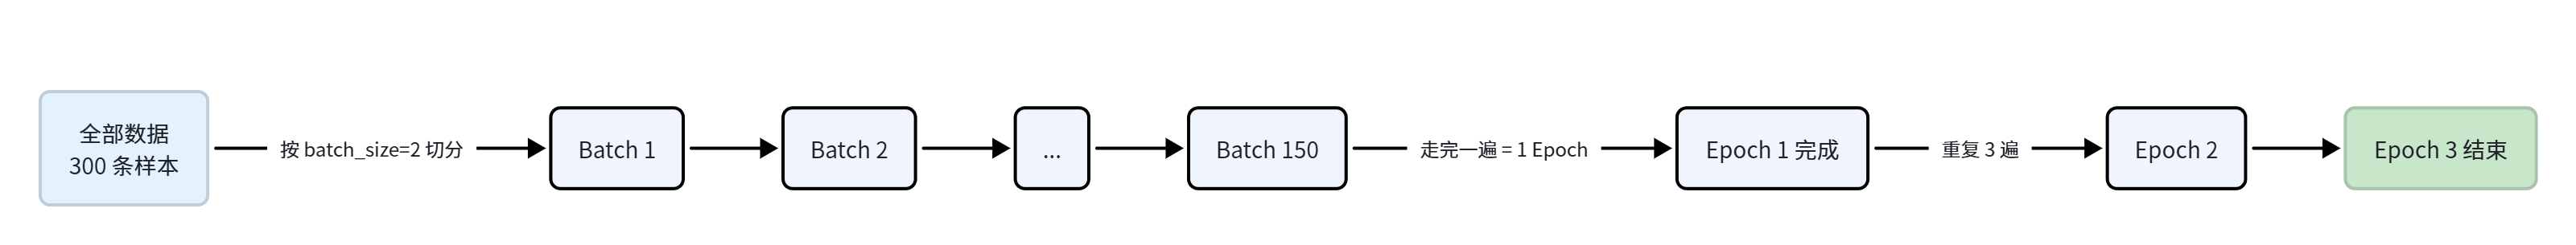
- 一个Epoch，完整的走一遍数据，Sample
- 一个Step，也就是走一遍Batch，前向+反向，更新一次参数
- 每个Epoch的Step数量，也就是Batch数量，Sample/Batch大小
- 3个Epoch的总Step数量，3*Step数量
- sample=300, batch_size=2, epoch=3, step=150

In [3]:
# 1. 造数据：y = 2x + 3 + 噪声
torch.manual_seed(0) # 设置PyTorch的随机数生成器种子，确保每次运行代码的随机序列相同
# [-1, 1] 区间内，按照线性均匀间隔生成 300 个数，然后在第1维增加维度
x = torch.linspace(-1,1,300).unsqueeze(1) 
# torch.randn_like(x)，和x张量相同形状的新张量，并且满足均匀分布，randn才是标准正态
y = 2*x+3+0.1*torch.rand_like(x)

# 2. 定义模型：y = w*x + b

# nn.Linear(in_features,out_features)
# 代表输入in_features个特征，输出out_features个特征

# model = nn.Linear(2,3) # 随机初始化w和b
# x_test = torch.tensor([[2.0,3.6]])
# y_test = model(x_test)
# print(y_test)

model = nn.Linear(1,1)
criterion = nn.MSELoss() # 损失函数
# 选择SGD优化器，更新model的参数
# model.parameters()返回模型中所有需要优化的参数
# 优化器会保存这些参数的引用，并在每次调用 optimizer.step() 时更新它们
optimizer = torch.optim.SGD(model.parameters(),lr=0.1)

# 3. 训练循环
EPOCHS = 3
BATCH_SIZE = 2
for epoch in range(EPOCHS):
    # 打乱顺序，避免每一次都跑一样的数据，相当于洗牌，然后重新组装batch

    perm = torch.randperm(x.size(0)) # 生成0,x.size(0)-1的随机序列
    x_shuf, y_shuf = x[perm], y[perm] # 随机序列perm作为索引，起到洗牌作用

    for step in range(0,len(x),BATCH_SIZE):
        xb = x_shuf[step:step+BATCH_SIZE]
        yb = y_shuf[step:step+BATCH_SIZE]

        y_pred = model(xb) # 前向
        loss = criterion(y_pred,yb)

        optimizer.zero_grad() # 清空上一步计算好的梯度
        loss.backward() # 反向求导
        optimizer.step() # 更新w，b的参数
    print(f"Epoch [{epoch+1}/{EPOCHS}] loss={loss.item():.4f} w={model.weight.item():.3f} b={model.bias.item():.3f}")


# 有个语法问题
# x_shuf = [1, 2, 3, ..., 10]  # 输入数据
# y_shuf = ['a', 'b', 'c', ..., 'j']  # 标签
# BATCH_SIZE = 3
# 如果是for step in range(0,len(x),BATCH_SIZE)
# step = 0 → xb = [1, 2, 3], yb = ['a', 'b', 'c']
# step = 3 → xb = [4, 5, 6], yb = ['d', 'e', 'f']
# step = 6 → xb = [7, 8, 9], yb = ['g', 'h', 'i']
# step = 9 → xb = [10],       yb = ['j']  # 最后一批不足 BATCH_SIZE

Epoch [1/3] loss=0.0006 w=1.999 b=3.046
Epoch [2/3] loss=0.0001 w=2.004 b=3.050
Epoch [3/3] loss=0.0005 w=2.003 b=3.055


### 训练流程
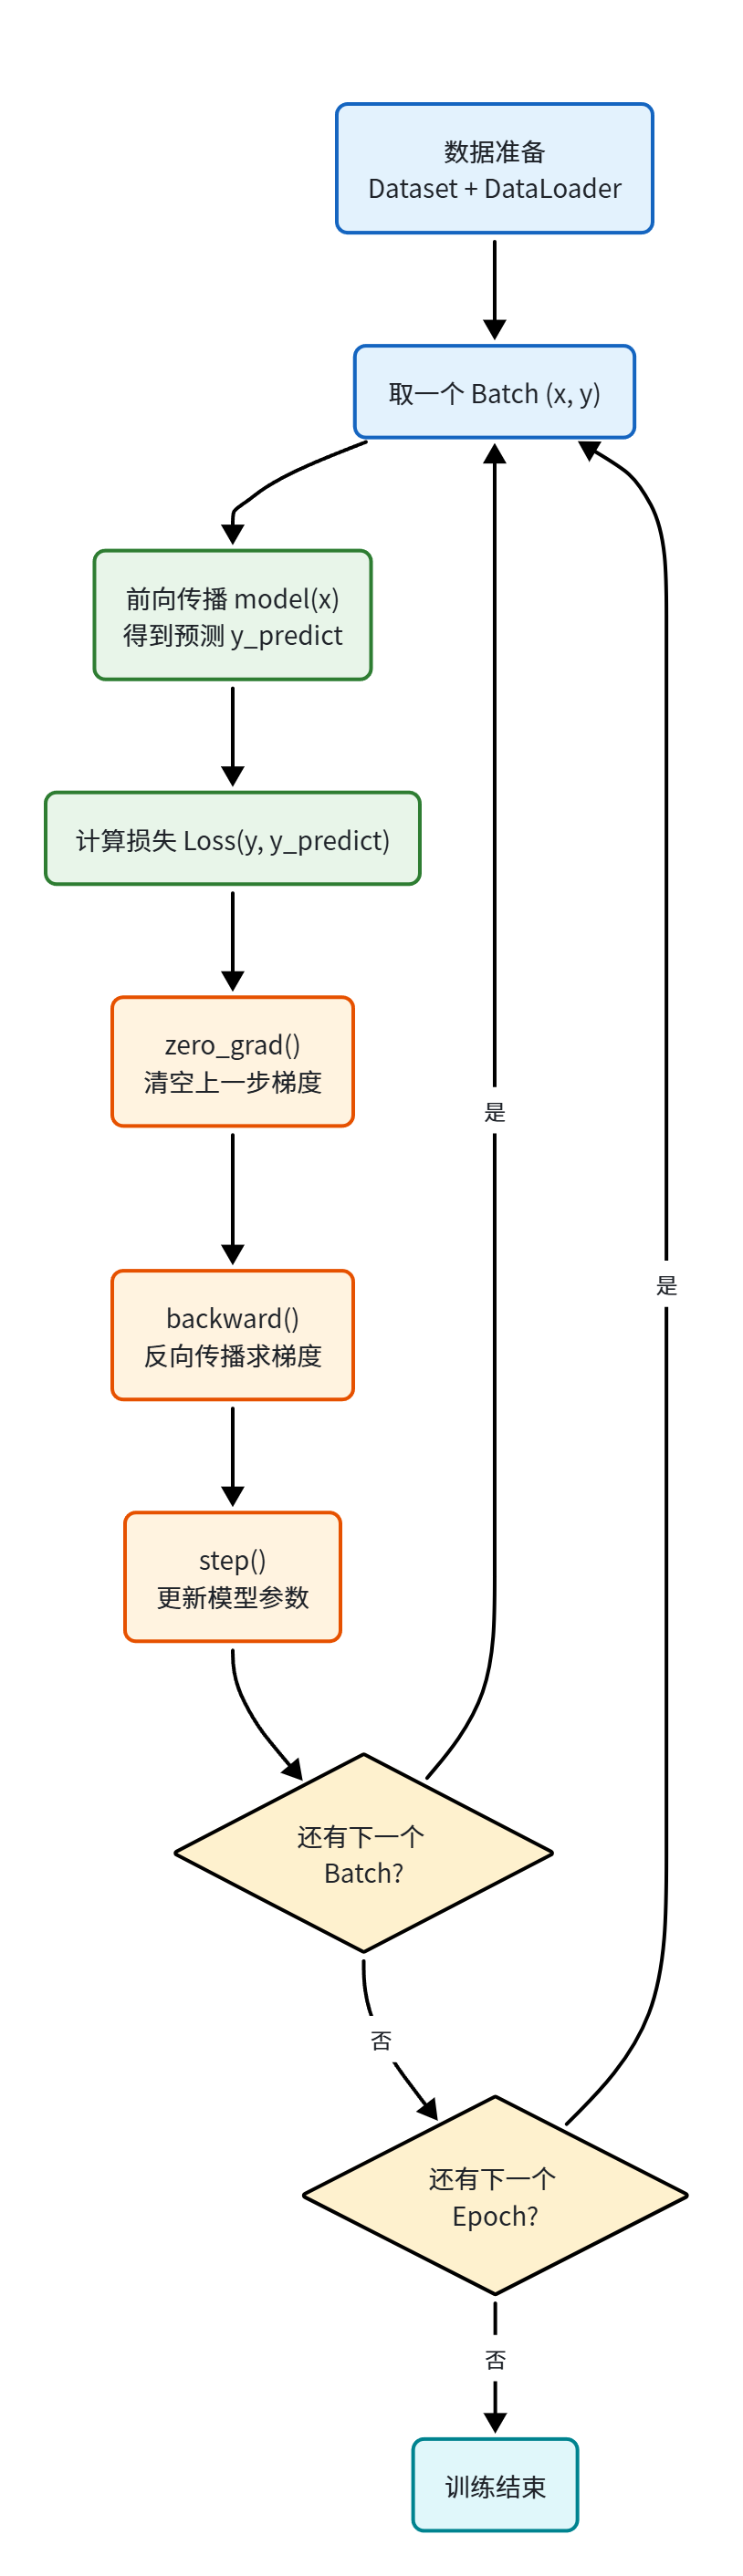